<a href="https://colab.research.google.com/github/szlot/myrepo/blob/main/OAK_of_Window_runner_2nd_base.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -U ultralytics

In [ ]:
from ultralytics import YOLO

print("Ultralytics installed successfully")

Ultralytics installed successfully


In [ ]:
from ultralytics import YOLO

model = YOLO("yolo26n.pt")

In [ ]:
from pathlib import Path
from urllib.parse import urlparse
import requests

# Direct URL to the video
video_url = "https://sporty-clips.mlb.com/d995f0c6-c71a-43dc-a62c-8c6f9d88185e.mp4"

# Create output directory
output_dir = Path("videos")
output_dir.mkdir(exist_ok=True)

# Extract filename directly from the URL or set a custom name
filename = Path(urlparse(video_url).path).name
video_path = output_dir / filename

# Stream and save the video
with requests.get(video_url, stream=True, timeout=60) as response:
    response.raise_for_status()
    with video_path.open("wb") as f:
        # 1 MB chunks
        for chunk in response.iter_content(chunk_size=1024 * 1024):
            if chunk:
                f.write(chunk)

print(f"Saved: {video_path}")
print(f"Size: {video_path.stat().st_size / 1_000_000:.1f} MB")

Saved: videos/d995f0c6-c71a-43dc-a62c-8c6f9d88185e.mp4
Size: 9.7 MB


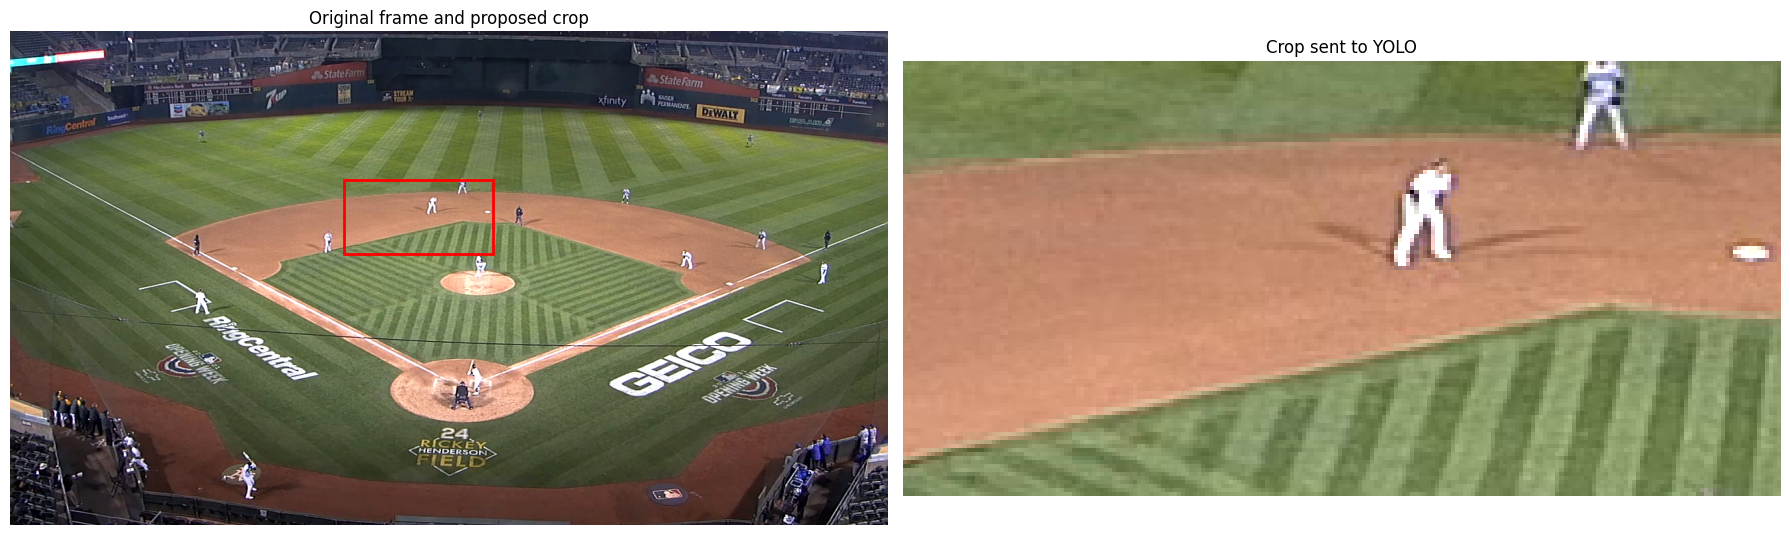

In [ ]:
# Display a frame and your proposed crop
# Start with a broad left-side region. The red rectangle shows exactly what you’re sending to YOLO. Adjust the four fractions until it contains the coach and room for extended arms.

import cv2
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

time_seconds = 2.0

cap = cv2.VideoCapture(str(video_path))
if not cap.isOpened():
    raise RuntimeError("Video could not be opened.")

cap.set(cv2.CAP_PROP_POS_MSEC, time_seconds * 1000)
ok, frame = cap.read()
cap.release()

if not ok:
    raise RuntimeError("Could not read frame. Try time_seconds = 0.")

# Starting region only — adjust after inspecting the image.
# Fractions: left, top, right, bottom
crop_region = (0.38, 0.30, 0.55, 0.45)

left, top, right, bottom = crop_region
assert 0 <= left < right <= 1
assert 0 <= top < bottom <= 1

height, width = frame.shape[:2]
x1, y1 = int(left * width), int(top * height)
x2, y2 = int(right * width), int(bottom * height)

roi = frame[y1:y2, x1:x2].copy()

fig, axes = plt.subplots(1, 2, figsize=(18, 8))

axes[0].imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
axes[0].add_patch(Rectangle(
    (x1, y1), x2 - x1, y2 - y1,
    fill=False, edgecolor="red", linewidth=2
))
axes[0].set_title("Original frame and proposed crop")

axes[1].imshow(cv2.cvtColor(roi, cv2.COLOR_BGR2RGB))
axes[1].set_title("Crop sent to YOLO")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

--> Best crossing frame identified!
Time: 5.00 seconds | Frame: 299
Distance to Trigger Line: 0.59 pixels


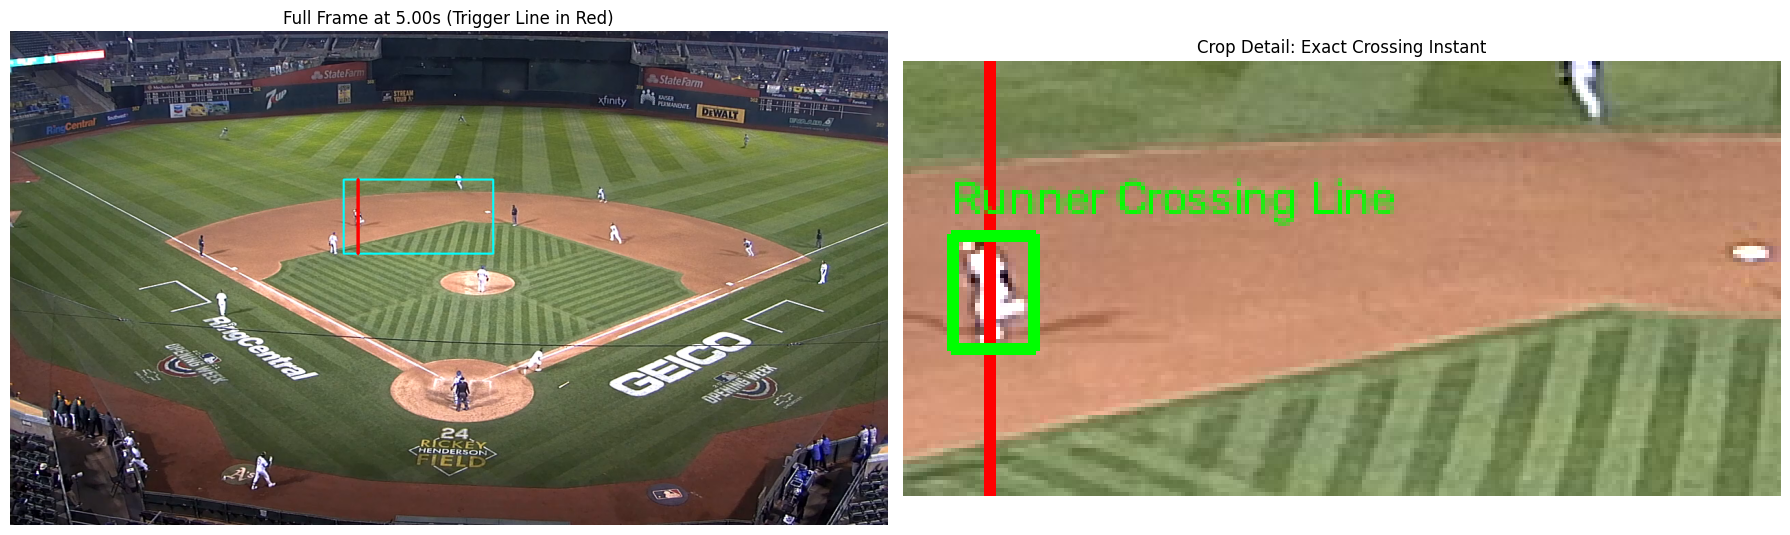

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Use the correct downloaded video path
video_path = Path("videos/d995f0c6-c71a-43dc-a62c-8c6f9d88185e.mp4")

# Open video
cap = cv2.VideoCapture(str(video_path))
if not cap.isOpened():
    raise RuntimeError(f"Could not open video at {video_path}")

fps = cap.get(cv2.CAP_PROP_FPS) or 30.0
h, w = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)), int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))

# Correct crop coordinates from the active crop_region (0.38, 0.30, 0.55, 0.45)
left_f, top_f, right_f, bottom_f = 0.38, 0.30, 0.55, 0.45
cx1, cy1 = int(left_f * w), int(top_f * h)
cx2, cy2 = int(right_f * w), int(bottom_f * h)
crop_width = cx2 - cx1

# Vertical trigger line is now set to 10% (0.10) of the crop width
trigger_x_relative = crop_width * 0.10
trigger_x_absolute = cx1 + trigger_x_relative

# Scan from 0.0 seconds
start_frame = 0
cap.set(cv2.CAP_PROP_POS_FRAMES, start_frame)

frame_idx = start_frame
detections = []

# Read all frames and track runner position
while cap.isOpened():
    ret, frame = cap.read()
    if not ret:
        break

    # Slice 2B-3B baseline crop
    crop = frame[cy1:cy2, cx1:cx2]

    # Run YOLO to find people inside the crop
    results = model.predict(source=crop, classes=[0], conf=0.15, imgsz=320, verbose=False)[0]
    boxes = results.boxes.xyxy.cpu().numpy()

    if len(boxes) > 0:
        # Find the runner: closest to the infield grass (largest bottom y coordinate, box[:, 3])
        runner_idx = np.argmax(boxes[:, 3])
        runner_box = boxes[runner_idx]
        runner_x = (runner_box[0] + runner_box[2]) / 2

        # Record runner info and how close they are to the trigger line
        detections.append({
            'frame_idx': frame_idx,
            'time_sec': frame_idx / fps,
            'runner_x_relative': runner_x,
            'runner_box': runner_box,
            'frame': frame.copy(),
            'crop': crop.copy(),
            'distance_to_trigger': abs(runner_x - trigger_x_relative)
        })

    frame_idx += 1

cap.release()

# Find the frame where the runner's horizontal center is closest to the trigger line
if len(detections) > 0:
    best_match = min(detections, key=lambda d: d['distance_to_trigger'])

    trigger_frame = best_match['frame_idx']
    trigger_time_sec = best_match['time_sec']
    trigger_image = best_match['frame']
    trigger_crop = best_match['crop']
    trigger_runner_box = best_match['runner_box']

    print(f"--> Best crossing frame identified!")
    print(f"Time: {trigger_time_sec:.2f} seconds | Frame: {trigger_frame}")
    print(f"Distance to Trigger Line: {best_match['distance_to_trigger']:.2f} pixels")

    # Visualize the full frame and the specific crop side-by-side
    fig, axes = plt.subplots(1, 2, figsize=(18, 8))

    # 1. Full Frame visualization
    full_vis = trigger_image.copy()
    cv2.rectangle(full_vis, (cx1, cy1), (cx2, cy2), (255, 255, 0), 2)  # Cyan crop boundary
    cv2.line(full_vis, (int(trigger_x_absolute), cy1), (int(trigger_x_absolute), cy2), (0, 0, 255), 3)  # Red trigger line

    axes[0].imshow(cv2.cvtColor(full_vis, cv2.COLOR_BGR2RGB))
    axes[0].set_title(f"Full Frame at {trigger_time_sec:.2f}s (Trigger Line in Red)")
    axes[0].axis("off")

    # 2. Detailed Crop visualization
    crop_vis = trigger_crop.copy()
    # Draw trigger line relative to the crop
    cv2.line(crop_vis, (int(trigger_x_relative), 0), (int(trigger_x_relative), cy2-cy1), (0, 0, 255), 2)
    # Draw runner bounding box in green to show who triggered it
    rx1, ry1, rx2, ry2 = map(int, trigger_runner_box)
    cv2.rectangle(crop_vis, (rx1, ry1), (rx2, ry2), (0, 255, 0), 2)
    cv2.putText(crop_vis, "Runner Crossing Line", (rx1, max(15, ry1-5)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.4, (0, 255, 0), 1)

    axes[1].imshow(cv2.cvtColor(crop_vis, cv2.COLOR_BGR2RGB))
    axes[1].set_title("Crop Detail: Exact Crossing Instant")
    axes[1].axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("Runner was not detected in any frame.")